In [376]:
import torch
import matplotlib.pyplot as plt
from torch import nn

**样本维度为 `(SKU数, 滑动窗口数, 窗口大小, 特征数)`，即每个商品生成多个时间切片作为样本，每个切片包含连续多天的多个特征。**

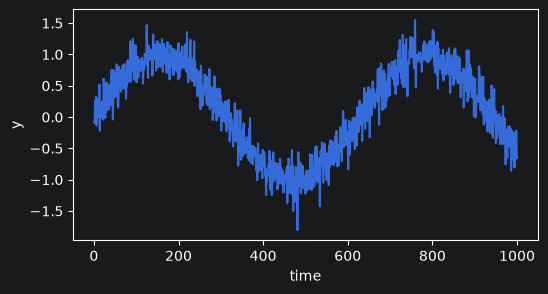

In [377]:
T=1000
time=(torch.arange(1, T+1,dtype=torch.float32))
epsilon=torch.normal(0,0.2,(T,))
x=torch.sin(0.01*time)+epsilon
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(time.numpy(), x.numpy())
ax.set_xlabel('time')
ax.set_ylabel('y')
plt.show()

In [378]:
tau=4
features=torch.zeros(T-tau,tau)
for i in range(tau):
    features[:,i]=x[i:T-tau+i]
    print(features)
print(features.shape)
labels=x[tau:].reshape((-1,1))
print(labels)
print(labels.shape)

tensor([[-0.0902,  0.0000,  0.0000,  0.0000],
        [-0.0212,  0.0000,  0.0000,  0.0000],
        [ 0.2572,  0.0000,  0.0000,  0.0000],
        ...,
        [-0.8080,  0.0000,  0.0000,  0.0000],
        [-0.3170,  0.0000,  0.0000,  0.0000],
        [-0.3603,  0.0000,  0.0000,  0.0000]])
tensor([[-0.0902, -0.0212,  0.0000,  0.0000],
        [-0.0212,  0.2572,  0.0000,  0.0000],
        [ 0.2572, -0.0626,  0.0000,  0.0000],
        ...,
        [-0.8080, -0.3170,  0.0000,  0.0000],
        [-0.3170, -0.3603,  0.0000,  0.0000],
        [-0.3603, -0.6703,  0.0000,  0.0000]])
tensor([[-0.0902, -0.0212,  0.2572,  0.0000],
        [-0.0212,  0.2572, -0.0626,  0.0000],
        [ 0.2572, -0.0626,  0.3270,  0.0000],
        ...,
        [-0.8080, -0.3170, -0.3603,  0.0000],
        [-0.3170, -0.3603, -0.6703,  0.0000],
        [-0.3603, -0.6703, -0.2175,  0.0000]])
tensor([[-0.0902, -0.0212,  0.2572, -0.0626],
        [-0.0212,  0.2572, -0.0626,  0.3270],
        [ 0.2572, -0.0626,  0.3270, -0

In [379]:
batch_size,n_train=16,600
# train_iter=d2l.load_array((features[:n_train],labels[:n_train]),
#                           batch_size,is_train=True)

from torch.utils.data import TensorDataset, DataLoader
dataset = TensorDataset(features[:n_train], labels[:n_train])
train_iter = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True
)

In [380]:
# 初始化网络权重
def init_weight(s):
    if type(s)==nn.Linear:
        torch.nn.init.xavier_uniform_(s.weight)

reduction 参数决定了损失函数返回的是"每个样本的独立损失"还是"所有样本聚合后的损失"，这是两种写法（loss.backward() vs l.sum().backward()）的根本区别。

In [381]:
def get_net():
    net= nn.Sequential(nn.Linear(4, 10),
                         nn.ReLU(),
                         nn.Linear(10, 1))
    net.apply(init_weight)
    return net
loss=nn.MSELoss(reduction='none')

In [382]:
def train(net,train_iter,loss,epochs,lt):
    trainer=torch.optim.Adam(net.parameters(),lr=lt)
    for(epoch) in range(epochs):
        total_loss=0
        num_samples = 0
        for X,y in train_iter:
            y_hat=net(X)
            l=loss(y_hat,y)
            sum_loss=l.sum()
            sum_loss.backward()
            trainer.step()
            total_loss=total_loss+sum_loss
            num_samples=num_samples+len(y)
            trainer.zero_grad()

        print(f'epoch {epoch} loss:{total_loss/num_samples}')


# 必须要保存模型，留后续使用

In [383]:
net=get_net()
train(net,train_iter,loss,5,0.01)

epoch 0 loss:0.3132631778717041
epoch 1 loss:0.06481203436851501
epoch 2 loss:0.057958029210567474
epoch 3 loss:0.05638173595070839
epoch 4 loss:0.0541604608297348


torch.Size([996, 1])


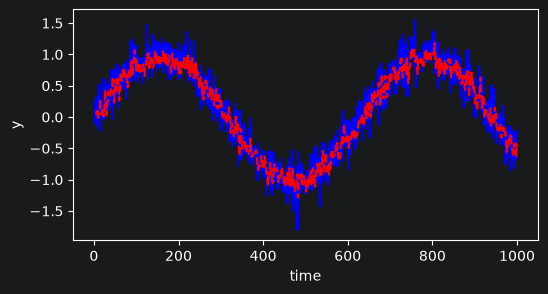

In [384]:
actual = labels.numpy().flatten()
preds = net(features).detach().numpy().flatten()
print(labels.shape)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(time, x.detach().numpy(), label='Actual', color='blue', linewidth=1.5)
ax.plot(time[tau:], preds, label='Predicted', color='red', linestyle='--', linewidth=1.5)
ax.set_xlabel('time')
ax.set_ylabel('y')
plt.show()